Найдено кадров: 40
https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W30_2B/l2b-v27-2026-221/6/level2_2025W30_2B_0082_1D6_spx_l2b-v27-2026-221.fits?center=224.130106041,-65.1948794976&size=0.1
Filename: C:\Users\aliev\.cache\astropy\download\url\cc09457fde29c0e9fb0da93d4ad9e1f1\contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       275   (58, 58)   float32   
  2  FLAGS         1 ImageHDU       185   (58, 58)   int32   
  3  VARIANCE      1 ImageHDU       119   (58, 58)   float32   
  4  ZODI          1 ImageHDU       122   (58, 58)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 9J, 162E]   
 ---- PRIMARY ---- 
 ---- IMAGE ---- 
BUNIT: MJy / sr
DETECTOR: 6
DATE: 2026-08-09T14:21:39.045
MJDREF: 0.0
DATE-OBS: 2025-07-24T22:30:38.799
MJD-OBS: 60880.937949062


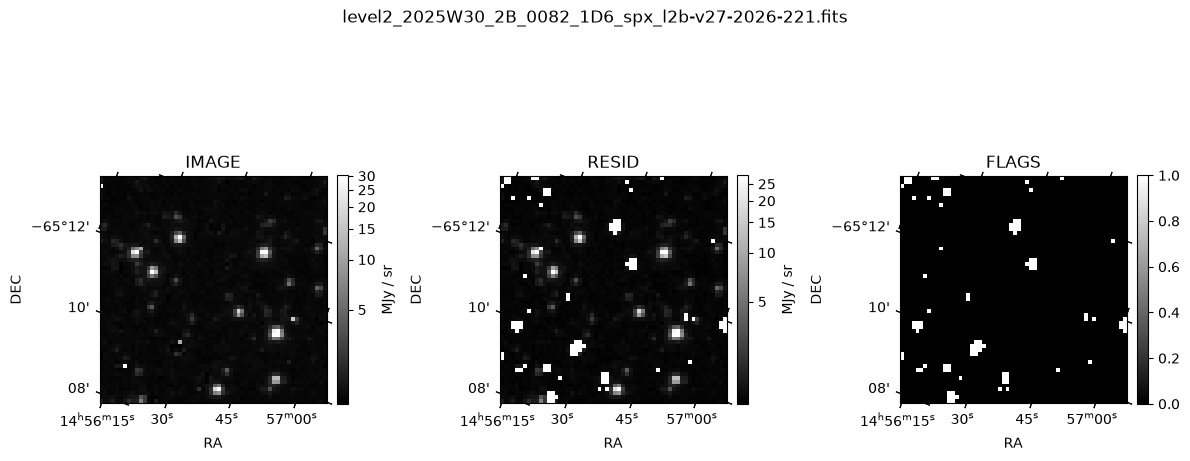

[0.00171323 0.00171145]
[6.16761748 6.16120205]
59
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : '' ''
CRVAL : 224.130106041 -65.1948794976
CRPIX : 30.0 30.0
PC1_1 PC1_2  : 1.0 0.0
PC2_1 PC2_2  : 0.0 1.0
CDELT : -0.001712336046186003 0.001712336046186003
NAXIS : 0  0
(59, 59)
<SkyCoord (ICRS): (ra, dec) in deg
    (224.13010604, -65.1948795)>
<SkyCoord (ICRS): (ra, dec) in deg
    (224.13010604, -65.1948795)>


In [24]:
from astropy.coordinates import SkyCoord
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.io import fits
from astropy.visualization import AsinhStretch, ImageNormalize, PercentileInterval
import astropy.wcs as wcs
import astropy.units as u
from astroquery.ipac.irsa import Irsa
import matplotlib.pyplot as plt
import numpy as np
import os

# SPHEREx Data Release 1 collection identifier and FITS header inspection keywords
COLLECTION = "spherex_dr1"
keywords = ["DATE", "MJD", "BUNIT", "DETECTOR"]
bad_flag_bits = [0, 1, 2, 6, 7, 9, 10, 11, 15, 19]

# Combine bad quality flag bit positions into a single integer bitmask
bad_bits = 0
for bit in bad_flag_bits:
    bad_bits |= (1 << bit)

# Print FITS header entries matching the predefined metadata keywords
def print_keywords(header, title):
    print(f" ---- {title} ---- ")
    for key, value in header.items():
        if any(k in key for k in keywords):
            print(f"{key}: {value}")

# Return a list of active bit indices (0-31) present across the flags array
def _active_bits(flags):
    combined = np.bitwise_or.reduce(np.unique(flags).astype(int))
    return [b for b in range(32) if combined & (1 << b)]

# Load science image, zodiacal background, quality flags, and WCS from a SPHEREx FITS file/URL
def load_spherex(path, verbose=True):
    with fits.open(path) as hdul:
        header = hdul["IMAGE"].header
        image = hdul["IMAGE"].data.astype(float)
        zodi = hdul["ZODI"].data.astype(float)
        flags = hdul["FLAGS"].data
        flags_header = hdul["FLAGS"].header
        w = wcs.WCS(header)

# Optionally print frame center coordinates and flag bit definitions
        if verbose:
            hdul.info()
            print_keywords(hdul["PRIMARY"].header, "PRIMARY")
            print_keywords(hdul["IMAGE"].header, "IMAGE")

    if verbose:
        ny, nx = image.shape
        sky_center = w.pixel_to_world(nx // 2, ny // 2)

        print(f"Центр кадра: {sky_center}")
        print(f"CRVAL: ({header['CRVAL1']}, {header['CRVAL2']})")
        print(" ---- FLAGS HEADER ---- ")
        for key, val in flags_header.items():
            if key.startswith("FLAG") or key.startswith("BIT"):
                print(f"{key}: {val}")
        print(f"Активные номера битов в кадре: {_active_bits(flags)}")

    return {"image": image,
            "zodi": zodi,
            "flags": flags,
            "wcs": w,
            "unit": header.get("BUNIT", ""),
            "title": os.path.basename(str(path).split("?")[0]),
            "mjd": header.get("MJD-AVG")}

# Query IRSA SIA for SPHEREx frames at given coordinates, filter by detector, sort by time, and subsample
def find_frames(coord, detector = 'SPHEREx-D6', max_frames=40):
    results = Irsa.query_sia(pos=(coord, 1 * u.arcmin), collection=COLLECTION)

    mask = results['energy_bandpassname'] == detector
    results = results[mask]

    results.sort('t_min')
    len_results = len(results)
    if len_results > max_frames:
        idx = np.linspace(0, len_results - 1, max_frames, dtype=int)
        results = results[idx]

    return results

# Append cutout center coordinates and field-of-view parameters to the FITS access URL
def cutout_url(access_url, coord, fov):
    base = str(access_url)

    ra = coord.ra.deg
    dec = coord.dec.deg

    url = f"{base}?center={ra},{dec}&size={fov}"
    return url

# Build a square tangent-plane (TAN) target WCS centered on the sky coordinates
def make_target_wcs(coord, fov, pix_deg):
    n = int(np.ceil(fov / pix_deg))
    print(n)

    target = wcs.WCS(naxis=2)
    target.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    target.wcs.crval = [coord.ra.deg, coord.dec.deg]
    target.wcs.crpix = [(n + 1) / 2, (n + 1)/ 2]
    target.wcs.cdelt = [-pix_deg, +pix_deg]
    return target, (n, n)

# Subtract zodiacal light background and mask flagged bad pixels with NaN
def clean(frame):
    residual = frame["image"] - frame["zodi"]
    mask = (frame["flags"] & bad_bits) != 0
    residual_masked = np.where(mask, np.nan, residual)
    return residual, mask, residual_masked

# Plot raw image, background-subtracted residual, and bad-pixel mask side-by-side with WCS axes
def show_image(image, mask, residual_masked, w, unit="", title=""):
    norm_main = ImageNormalize(image, interval=PercentileInterval(99.5), stretch=AsinhStretch())

    if np.any(np.isfinite(residual_masked)):
        norm_res = ImageNormalize(residual_masked, interval=PercentileInterval(99.5), stretch=AsinhStretch())
    else:
        norm_res = None
        print(f"Проблемный кадр: {title}")

    panel = [
        (image, norm_main, "IMAGE", unit),
        (residual_masked, norm_res, "RESID", unit),
        (mask, None, "FLAGS", None)
    ]

    fig = plt.figure(figsize=[12.0, 6.0])
    for i, (data, norm, label, cbar_label) in enumerate(panel, start=1):
        ax = fig.add_subplot(1, len(panel), i, projection=w)
        im = ax.imshow(data, norm=norm, cmap="gray", origin="lower")
        ax.set_title(label)

        if w is not None:
            ax.set_xlabel("RA")
            ax.set_ylabel("DEC")

        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        if cbar_label is not None:
            cbar.set_label(cbar_label)
    if title:
        fig.suptitle(title)

    fig.tight_layout()
    plt.show()

# HTTP 502 Proxy Error occurs on the external NASA/IPAC IRSA server side:
# the Caltech gateway temporarily fails to receive a response from the internal SIA service.
if __name__ == "__main__":
    # Define target sky coordinates and field of view (in degrees)
    coord = SkyCoord(224.130106041, -65.1948794976, unit="deg")
    foo = 0.1

    # Search for matching frames and build cutout URL for the first result
    frames = find_frames(coord)
    print(f"Найдено кадров: {len(frames)}")

    url = cutout_url(frames["access_url"][0], coord, foo)
    print(url)

    # Load FITS cutout, subtract zodiacal background, apply bad-pixel mask, and display panels
    fr = load_spherex(url, verbose=True)
    residual, mask, residual_masked = clean(fr)
    print(fr["image"].shape)

    show_image(fr["image"], mask, residual_masked, fr["wcs"], unit=fr["unit"], title=fr["title"])

    # Compute pixel scale and verify target WCS grid alignment with the input coordinates
    scales = proj_plane_pixel_scales(fr["wcs"])
    print(scales)
    print(scales * 3600)
    pix_deg = scales.mean()

    target, shape_out = make_target_wcs(coord, 0.1, pix_deg)
    print(target)
    print(shape_out)
    print(target.pixel_to_world((shape_out[1] - 1) / 2, (shape_out[0] - 1) / 2))
    print(coord)
